# SMS Spam Collection: Text Analysis and Machine Learning

CSCI461 Introduction to Big Data — Assignment 1. This notebook studies the approved UCI SMS Spam Collection. Each record is one SMS labeled as `ham` or `spam`. The original text is retained while a normalized `cleaned_text` field is created.

The analysis covers data understanding and cleaning, transformations, sampling, text features and frequency analysis, supervised TF-IDF classification, and unsupervised K-Means. All generated CSV, text reports, and figures are saved under `output/`.

## Reproducible analysis

The project implementation is shared with the notebook so Docker verification and interactive execution use identical analysis code. Run **Kernel → Restart Kernel and Run All Cells** to recreate the reports.


============== Dataset understanding ==============
Source shape: (5574, 2)

Head:
 label                                                                                                                                                        text
  ham                                             Go until jurong point, crazy.. Available only in bugis n great world la e buffet... Cine there got amore wat...
  ham                                                                                                                               Ok lar... Joking wif u oni...
 spam Free entry in 2 a wkly comp to win FA Cup final tkts 21st May 2005. Text FA to 87121 to receive entry question(std txt rate)T&C's apply 08452810075over18's
  ham                                                                                                           U dun say so early hor... U c already then say...
  ham                                                                                               Nah I

Shape before cleaning: (5574, 2)
Shape after cleaning: (5158, 3)
Decision: remove exact duplicate labeled messages to avoid repeated records overweighting the results; remove unusable empty messages; preserve original text and fill missing message text before normalization.
Empty normalized messages removed: 2
Original text preserved: True

Created transformations: cleaned_text, label_code, character-count normalization, word-count bins, and numeric text features.

Numerical feature summary:
        char_count  word_count  unique_word_count  avg_word_length  digit_count
count     5158.00     5158.00            5158.00          5158.00      5158.00
mean        79.17       16.25              14.33             3.83         2.18
std         58.28       11.76               8.82             0.71         5.99
min          2.00        1.00               1.00             1.00         0.00
25%         36.00        8.00               7.00             3.36         0.00
50%         61.00       13.0


loc: spam messages with original text (first five):
 label                                                                                                                                                          text
 spam   Free entry in 2 a wkly comp to win FA Cup final tkts 21st May 2005. Text FA to 87121 to receive entry question(std txt rate)T&C's apply 08452810075over18's
 spam           FreeMsg Hey there darling it's been 3 week's now and no word back! I'd like some fun you up for it still? Tb ok! XxX std chgs to send, £1.50 to rcv
 spam WINNER!! As a valued network customer you have been selected to receivea £900 prize reward! To claim call 09061701461. Claim code KL341. Valid 12 hours only.
 spam    Had your mobile 11 months or more? U R entitled to Update to the latest colour mobiles with camera for Free! Call The Mobile Update Co FREE on 08002986030
 spam                      SIX chances to win CASH! From 100 to 20,000 pounds txt> CSH11 and send to 87575. Cost 150p/day, 6da

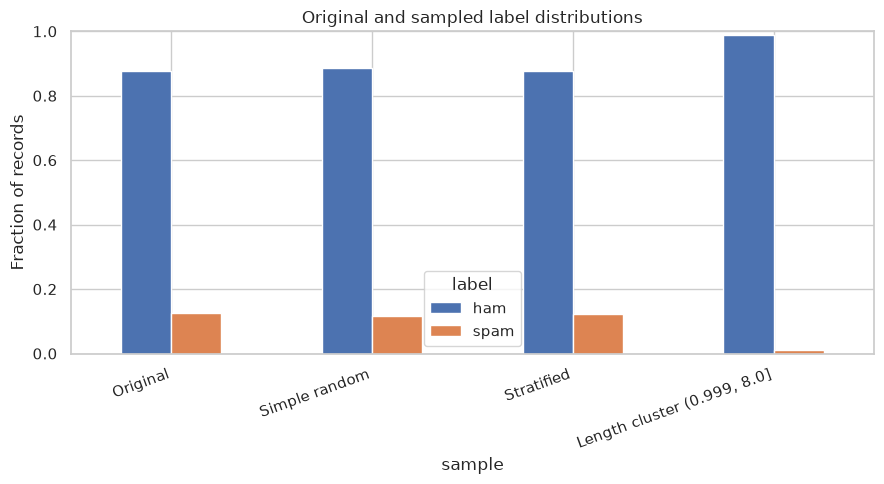


============== Text analysis ==============
Total tokens: 83843
Unique words: 7748
Average words per record: 16.25

Top 20 words, before and after English stopword removal:
  rank including_stopwords  count_including_stopwords excluding_stopwords  count_excluding_stopwords
    1              number                       3960              number                       3960
    2                   i                       2859                   u                       1087
    3                 you                       2139                   s                        565
    4                  to                       2065                   t                        465
    5                   a                       1316                   m                        440
    6                 the                       1247                just                        348
    7                   u                       1087                  ur                        322
    8                 and

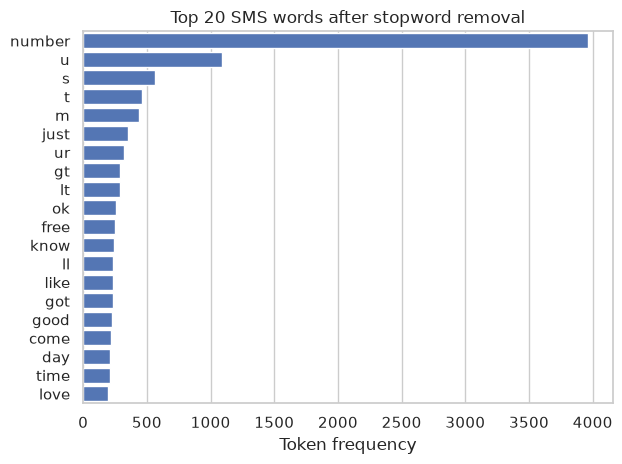


Average length comparison:
        average_characters  average_words
label                                   
ham                 70.89          14.78
spam               137.41          26.67

Top 10 words for ham (stopwords removed): [('number', 1188), ('u', 938), ('s', 481), ('m', 397), ('t', 388), ('gt', 288), ('lt', 287), ('just', 282), ('ok', 256), ('ll', 233)]

Top 10 words for spam (stopwords removed): [('number', 2772), ('free', 192), ('p', 154), ('u', 149), ('txt', 136), ('ur', 119), ('stop', 116), ('text', 108), ('mobile', 107), ('reply', 96)]


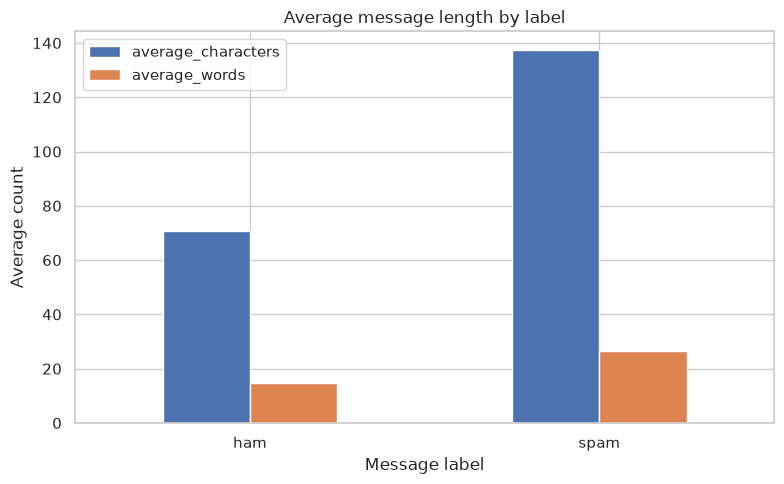


============== Correlation ==============
                   char_count  word_count  unique_word_count  avg_word_length  digit_count
char_count              1.000       0.980              0.958            0.183        0.376
word_count              0.980       1.000              0.974            0.055        0.349
unique_word_count       0.958       0.974              1.000            0.045        0.302
avg_word_length         0.183       0.055              0.045            1.000        0.304
digit_count             0.376       0.349              0.302            0.304        1.000


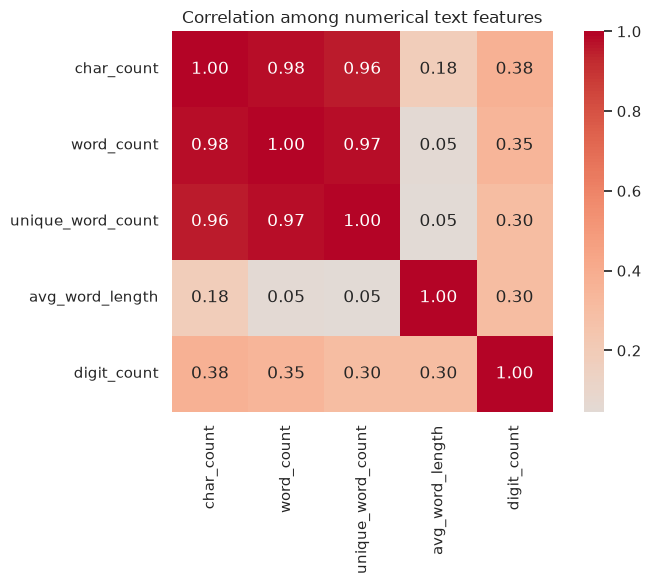

Correlations show association, not causation; message length and token counts are mechanically related, but correlation alone cannot establish why.

============== Supervised TF-IDF classification ==============



Multinomial Naive Bayes:
 accuracy          0.9729
precision_spam    1.0000
recall_spam       0.7812
f1_spam           0.8772
              precision    recall  f1-score   support

         ham       0.97      1.00      0.98       904
        spam       1.00      0.78      0.88       128

    accuracy                           0.97      1032
   macro avg       0.98      0.89      0.93      1032
weighted avg       0.97      0.97      0.97      1032


Logistic Regression:
 accuracy          0.9874
precision_spam    0.9457
recall_spam       0.9531
f1_spam           0.9494
              precision    recall  f1-score   support

         ham       0.99      0.99      0.99       904
        spam       0.95      0.95      0.95       128

    accuracy                           0.99      1032
   macro avg       0.97      0.97      0.97      1032
weighted avg       0.99      0.99      0.99      1032



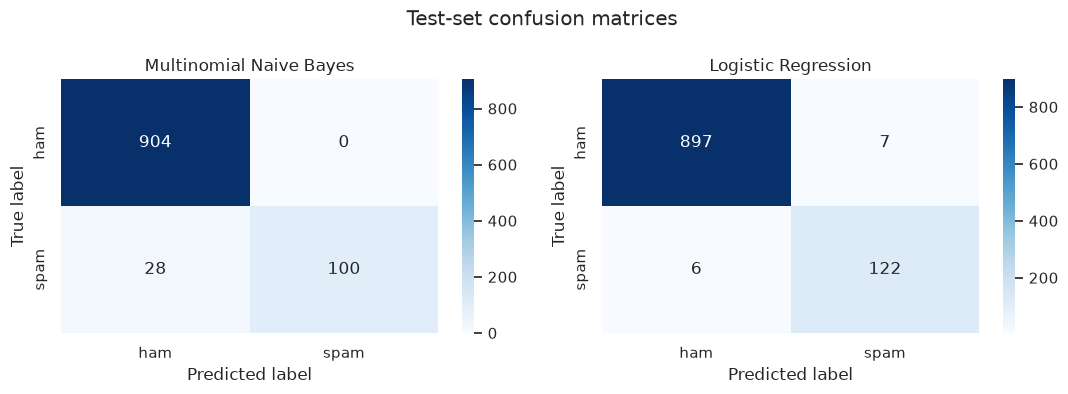


============== K-Means clustering ==============


k=2: sampled cosine silhouette=0.0143


k=3: sampled cosine silhouette=0.0151


k=4: sampled cosine silhouette=0.0208

Selected k=4 by the highest sampled cosine silhouette score.
Cluster sizes:
 cluster
0    4089
1     699
2     168
3     202


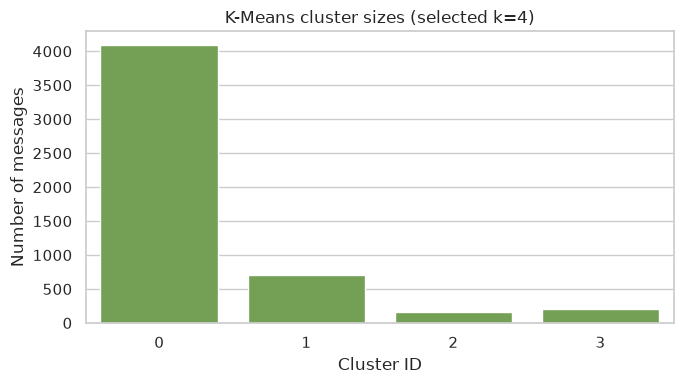


============== Evidence-based insights ==============
1. Observation: ham accounts for 87.6% of cleaned records. Evidence: 4516 ham and 642 spam messages remain. Interpretation: the class imbalance makes per-class recall/F1 important alongside accuracy.
2. Observation: spam messages average 137.4 characters versus 70.9 for ham (ratio 1.94). Evidence: grouped character-count means shown in the group-comparison output. Interpretation: message length differs by class in this corpus, but length alone is not a reliable decision rule.
3. Observation: the most frequent stopword-filtered ham token is 'number' (1188 occurrences), while the spam leader is 'number' (2772 occurrences). Evidence: per-label top-word counts. Interpretation: class-specific vocabulary provides useful but corpus-dependent signal.
4. Observation: Logistic Regression achieved spam F1=0.949 and spam recall=0.953 on the stratified test set. Evidence: held-out classification metrics. Interpretation: this balances false posi


Cleaned data saved to /home/jovyan/work/bd-a1/output/cleaned_data.csv
Reports and figures saved under /home/jovyan/work/bd-a1/output


{'__name__': '__main__',
 '__doc__': 'Reproducible SMS spam analysis used by notebook/analysis.ipynb.',
 '__package__': '',
 '__loader__': None,
 '__spec__': None,
 '__file__': '/home/jovyan/work/bd-a1/analysis.py',
 '__cached__': None,
 '__builtins__': {'__name__': 'builtins',
  '__doc__': "Built-in functions, types, exceptions, and other objects.\n\nThis module provides direct access to all 'built-in'\nidentifiers of Python; for example, builtins.len is\nthe full name for the built-in function len().\n\nThis module is not normally accessed explicitly by most\napplications, but can be useful in modules that provide\nobjects with the same name as a built-in value, but in\nwhich the built-in of that name is also needed.",
  '__package__': '',
  '__loader__': _frozen_importlib.BuiltinImporter,
  '__spec__': ModuleSpec(name='builtins', loader=<class '_frozen_importlib.BuiltinImporter'>, origin='built-in'),
  '__build_class__': <function __build_class__>,
  '__import__': <function __import

In [1]:
from pathlib import Path
import runpy

project_root = Path.cwd()
while project_root != project_root.parent and not (project_root / "analysis.py").is_file():
    project_root = project_root.parent
if not (project_root / "analysis.py").is_file():
    raise FileNotFoundError("Could not locate analysis.py from the notebook working directory")
runpy.run_path(str(project_root / "analysis.py"), run_name="__main__")

## Interpretation reminder

K-Means is unsupervised: cluster identifiers are arbitrary and are not expected to match the ham/spam label values. The reported silhouette score measures geometric separation in the TF-IDF representation, not classification accuracy. Correlation between numerical text features describes co-variation, not cause and effect.